In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [37]:
album = pd.read_csv("Album.csv")
artist= pd.read_csv("Artist.csv")
customer = pd.read_csv("Customer.csv")
employee = pd.read_csv("Employee.csv")
genre = pd.read_csv("Genre.csv")
invoice = pd.read_csv("Invoice.csv")
invoice_line = pd.read_csv("InvoiceLine.csv")
media = pd.read_csv("MediaType.csv")
playlist = pd.read_csv("Playlist.csv")
playlist_track = pd.read_csv("PlayListTrack.csv")
track = pd.read_csv("Track.csv")


# Usamos solo invoice, pero preparamos la fecha
df_ventas = invoice.copy()
df_ventas['InvoiceDate'] = pd.to_datetime(df_ventas['InvoiceDate'])
df_ventas['Mes_Año'] = df_ventas['InvoiceDate'].dt.to_period('M')

# Agrupar las ventas totales por mes
ventas_mensuales = df_ventas.groupby('Mes_Año')['Total'].sum()
display(ventas_mensuales.head(2))
# Convertir el índice (period) a string para que matplotlib lo grafique sin problemas
ventas_mensuales.index = ventas_mensuales.index.astype(str)
display(ventas_mensuales.head(2))

# Cruzar Tracks con Media Types para tener el nombre del formato
df_pistas_media = pd.merge(track, media, on="MediaTypeId", suffixes=('_Track', '_Media'))

# Convertir milisegundos a minutos y bytes a megabytes
df_pistas_media['Minutos'] = df_pistas_media['Milliseconds'] / 60000
df_pistas_media['Megabytes'] = df_pistas_media['Bytes'] / (1024 * 1024)

# Filtrar valores atípicos extremos para una mejor visualización
df_scatter = df_pistas_media[df_pistas_media['Minutos'] < 20]
df_scatter.head()


# Cruzar líneas de factura con canciones y luego con géneros
df_inv_trk = pd.merge(invoice_line, track, on="TrackId")
df_ventas_generos = pd.merge(df_inv_trk, genre, on="GenreId", suffixes=('_Track', '_Genre'))

# Sumar las ventas (Quantity * UnitPrice) por género
df_ventas_generos['Monto'] = df_ventas_generos['UnitPrice_x'] * df_ventas_generos['Quantity']
ingresos_por_genero = df_ventas_generos.groupby('Name_Genre')['Monto'].sum().sort_values(ascending=False)

# Tomar el top 5
top_5_generos = ingresos_por_genero.head(5)
top_5_generos

Mes_Año
2021-01    35.64
2021-02    37.62
Freq: M, Name: Total, dtype: float64

Mes_Año
2021-01    35.64
2021-02    37.62
Name: Total, dtype: float64

Name_Genre
Rock                  826.65
Latin                 382.14
Metal                 261.36
Alternative & Punk    241.56
TV Shows               93.53
Name: Monto, dtype: float64

In [ ]:
print(album.columns)
print(artist.columns)
print(customer.columns)
print(employee.columns)
print(genre.columns)
print(invoice.columns)
print(invoice_line.columns)
print(media.columns)
print(playlist.columns)
print(playlist_track.columns)
print(track.columns)

Index(['AlbumId', 'Title', 'ArtistId'], dtype='str')
Index(['ArtistId', 'Name'], dtype='str')
Index(['CustomerId', 'FirstName', 'LastName', 'Company', 'Address', 'City',
       'State', 'Country', 'PostalCode', 'Phone', 'Fax', 'Email',
       'SupportRepId'],
      dtype='str')
Index(['EmployeeId', 'LastName', 'FirstName', 'Title', 'ReportsTo',
       'BirthDate', 'HireDate', 'Address', 'City', 'State', 'Country',
       'PostalCode', 'Phone', 'Fax', 'Email'],
      dtype='str')
Index(['GenreId', 'Name'], dtype='str')
Index(['InvoiceId', 'CustomerId', 'InvoiceDate', 'BillingAddress',
       'BillingCity', 'BillingState', 'BillingCountry', 'BillingPostalCode',
       'Total', 'Fecha', 'año'],
      dtype='str')
Index(['InvoiceLineId', 'InvoiceId', 'TrackId', 'UnitPrice', 'Quantity'], dtype='str')
Index(['MediaTypeId', 'Name'], dtype='str')
Index(['PlaylistId', 'Name'], dtype='str')
Index(['PlaylistId', 'TrackId'], dtype='str')
Index(['TrackId', 'Name', 'AlbumId', 'MediaTypeId', 'GenreId

#### 1. Con el DataFrame de customer, haz un countplot horizontal del número de clientes por país, ordenando de mayor a menor.

In [38]:
customer.head()

,CustomerId,FirstName,LastName,Company,Address,City,State,Country,PostalCode,Phone,Fax,Email,SupportRepId
0,1,Luís,Gonçalves,Embraer - Empresa Brasileira de Aeronáutica S.A.,"Av. Brigadeiro Faria Lima, 2170",São José dos Campos,SP,Brazil,12227-000,+55 (12) 3923-5555,+55 (12) 3923-5566,luisg@embraer.com.br,3
1,2,Leonie,Köhler,NaN,Theodor-Heuss-Straße 34,Stuttgart,NaN,Germany,70174,+49 0711 2842222,NaN,leonekohler@surfeu.de,5
2,3,François,Tremblay,NaN,1498 rue Bélanger,Montréal,QC,Canada,H2G 1A7,+1 (514) 721-4711,NaN,ftremblay@gmail.com,3
3,4,Bjørn,Hansen,NaN,Ullevålsveien 14,Oslo,NaN,Norway,0171,+47 22 44 22 22,NaN,bjorn.hansen@yahoo.no,4
4,5,František,Wichterlová,JetBrains s.r.o.,Klanova 9/506,Prague,NaN,Czech Republic,14700,+420 2 4172 5555,+420 2 4172 5555,frantisekw@jetbrains.com,4


<Axes: xlabel='count', ylabel='Country'>

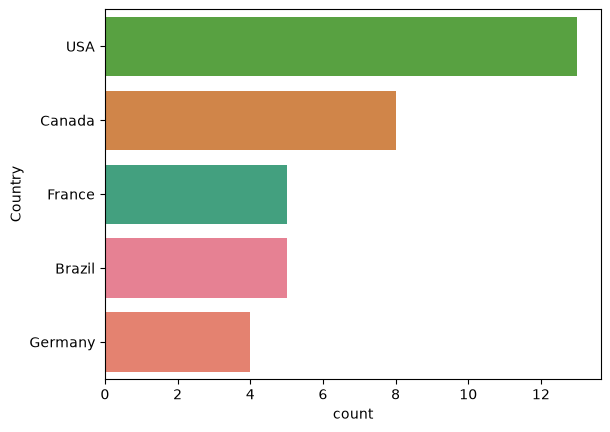

In [39]:
df1 = customer
df1 = df1.groupby("Country")["CustomerId"].count().sort_values(ascending=False).nlargest(5).index
sns.countplot(data=customer, y="Country", order=df1, hue="Country")

#### 2.- Haz un boxplot del Total de las facturas por país, solo para los 5 países con más ingresos.
¿Algún país tiene facturas atípicamente grandes?

<Axes: xlabel='BillingCountry', ylabel='Total'>

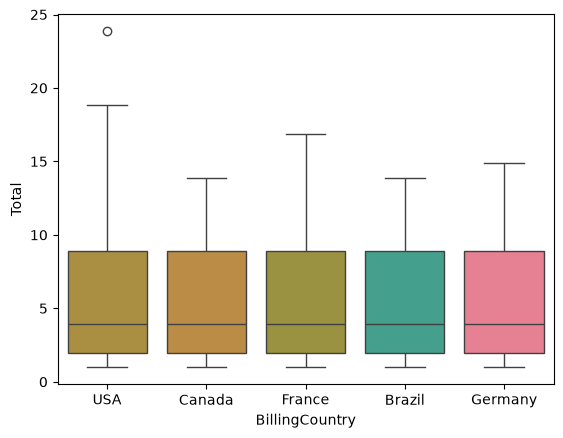

In [40]:
df2 = invoice.groupby("BillingCountry")["Total"].count().sort_values(ascending=False).nlargest(5).index
sns.boxplot(data=invoice, x="BillingCountry",y="Total", order=df2, hue="BillingCountry")

#### 3. Une invoice con customer (por CustomerId) y luego con employee (SupportRepId de customer corresponde a EmployeeId; usa left_on/right_on) y grafica con barplot los ingresos totales que atiende cada representante de soporte

<Axes: xlabel='SupportRepId', ylabel='Total'>

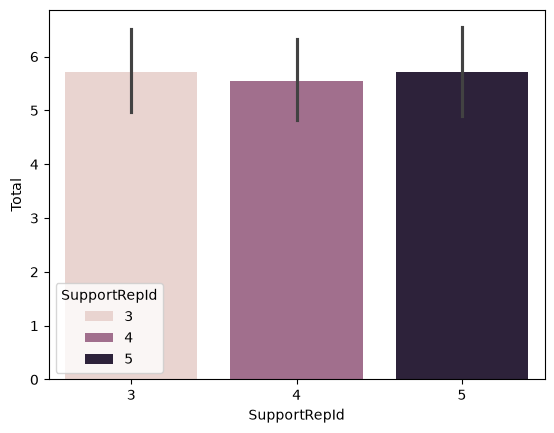

In [41]:
merge = invoice.merge(customer, on="CustomerId", how="left")
merge2= merge.merge(employee, left_on="SupportRepId", right_on="EmployeeId", how="left")
sns.barplot(data=merge2, y="Total", x="SupportRepId", hue="SupportRepId")


#### 4.- Crea una figura de 1×2 con sharey=True: a la izquierda el violinplot de duración para "Rock" y "Latin"; a la derecha el stripplot de los mismos datos.

<Axes: xlabel='Name_x', ylabel='Milliseconds'>

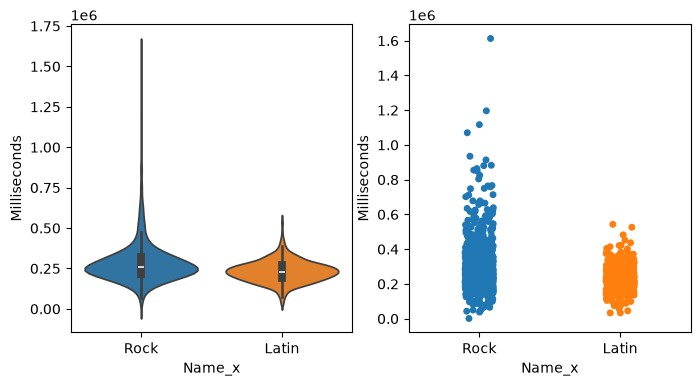

In [46]:
df4 = genre.merge(track, on="GenreId", how="left")
RL = df4[(df4["Name_x"]=="Rock")|(df4["Name_x"]=="Latin")]

fig, axes = plt.subplots(1,2, figsize=(8,4), sharey=False)

sns.violinplot(data=RL, x= "Name_x", y="Milliseconds", hue="Name_x", ax=axes[0])
sns.stripplot(data=RL, x="Name_x", y="Milliseconds",hue="Name_x", ax=axes[1] )

#### 5. Construye un tablero de 2 × 3 con seis gráficas distintas de Chinook. Cada panel debe tener título, etiquetas de ejes en español y la figura un suptitle. Guárdalo como PNG a 200 dpi

In [ ]:
invoice["año"] = invoice["InvoiceDate"].dt.year
invoice["mes"] = invoice["InvoiceDate"].dt.month
mensual = invoice.groupby(["año","mes"], as_index=False)["Total"].sum()


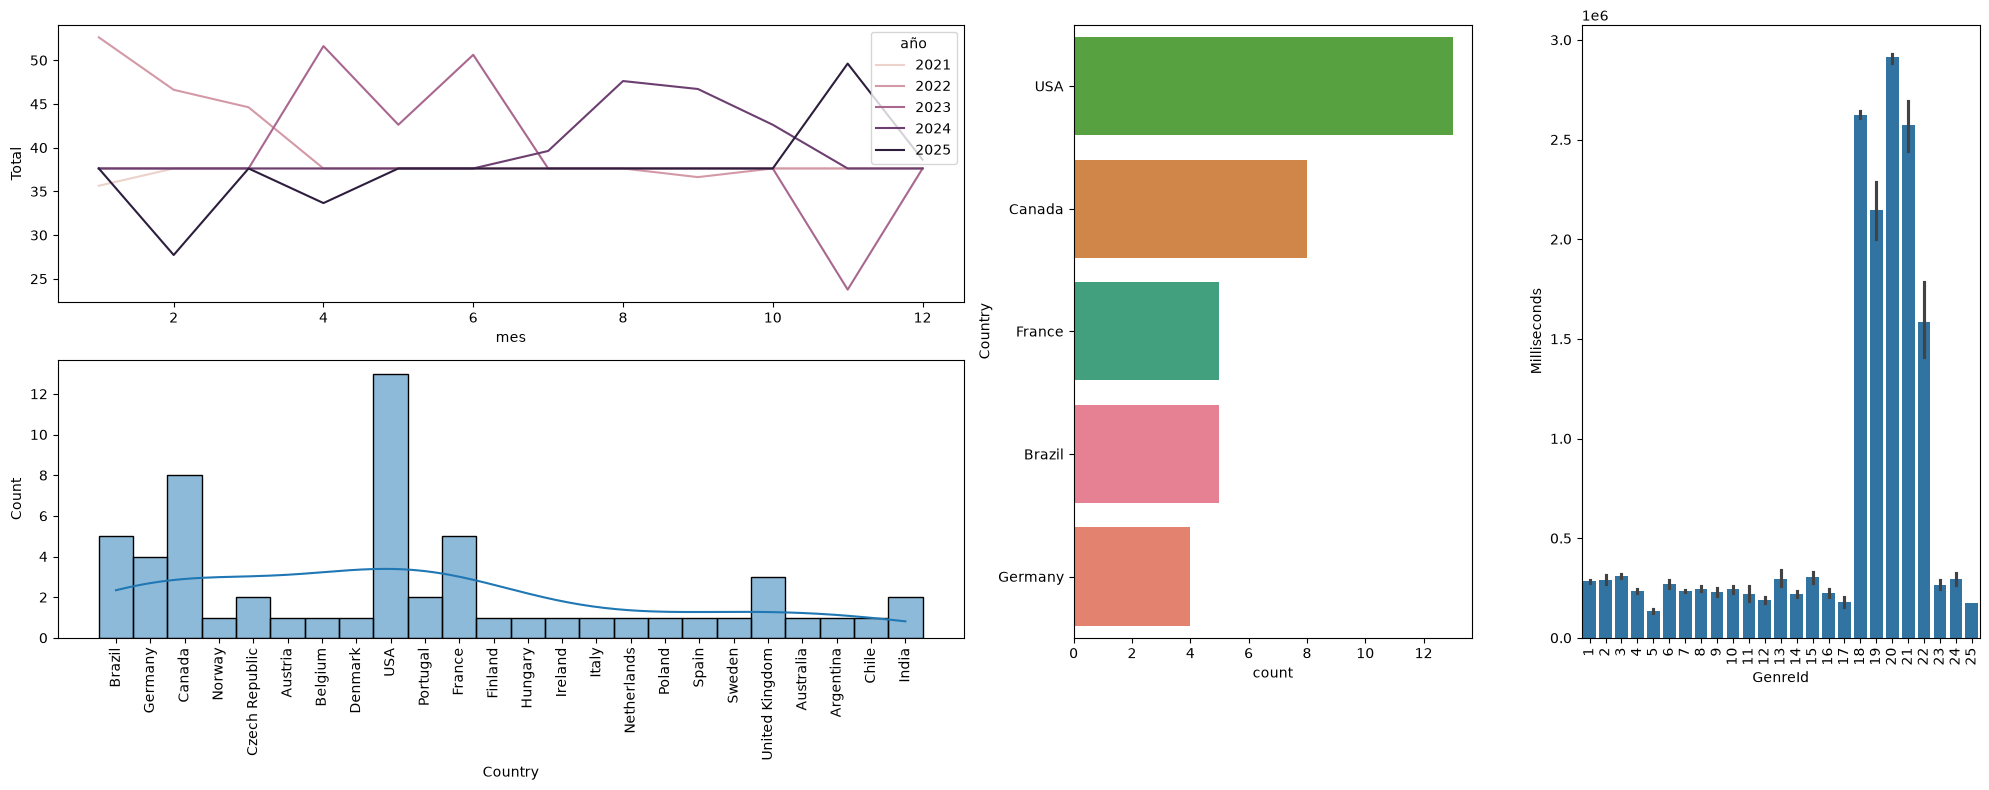

In [99]:
fig, axd = plt.subplot_mosaic("AABC;DDBC" , figsize=(20,8))
troca = track
sns.barplot(data = track, x="GenreId", y="Milliseconds", ax=axd["C"])
sns.countplot(data=customer, y="Country", order =df1,hue="Country", ax=axd["B"])
sns.lineplot(data= mensual,x="mes", y="Total", hue="año", ax=axd["A"])
sns.histplot(data=customer,x="Country",kde=True,bins=50 ,ax=axd["D"])

axd["D"].tick_params(axis="x",rotation=90)
axd["C"].tick_params(axis="x",rotation=90)
fig.tight_layout()

#### 6. Reproduce el heatmap de país × año, pero con el número de facturas en lugar del ingreso (aggfunc="count"). ¿Cambia la historia?

<Axes: xlabel='año', ylabel='BillingCountry'>

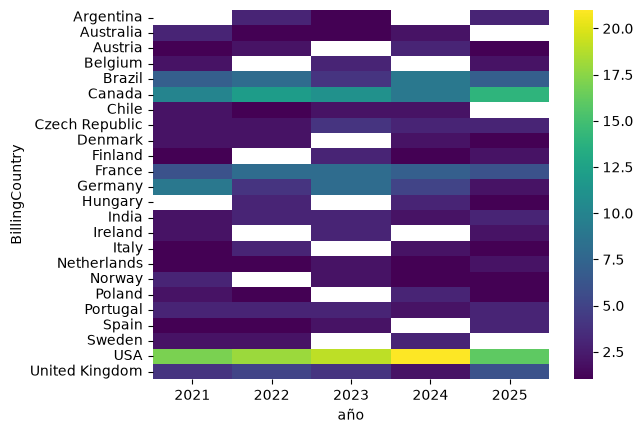

In [57]:
invoice["InvoiceDate"] = pd.to_datetime(invoice["InvoiceDate"])
invoice["año"] = invoice["InvoiceDate"].dt.year
df6 = invoice
df6 = df6.pivot_table(values ="InvoiceId", index="BillingCountry",columns="año", aggfunc="count")
sns.heatmap(data=df6, cmap="viridis")